In [81]:
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt
import time

In [98]:
# Parameters
M = 11                  # Number of vehicles in the platoon
lambda_m = 6e6          # Total data [bps]
lambda_bar_m = 4e6      # Offloaded data [bps]
B = 10e6                # Bandwith [Hz]
p_max_l = 50.0          # Max. local computing power [W]
p_max_o = 50.0           # Max. transmitting power [W]
kappa_m = 1e-28         # Effective switched capacitance (PM)
L0 = 1000               # CPU cycles per bit
g0 = 1e-4               # Channel gain at 1 meter
alpha = 2.0             # Path loss exponent
sigma2 = 1e-9           # Noise power (-174dBm/Hz * B) [W]
epsilon = 1e-5          # SINR threshold lower bound (to avoid gamma_m = 0)
d = 3                   # Distances between each PM m from the PL [m]

# Distances from PM m to the PL
distances = np.array([(m+1)*d for m in range(M)])

# Channel gains
h_m = g0 * ((distances)**(-alpha/2))

In [99]:
# Problem definition
p_l = cp.Variable(M, pos=True)    # Local computing power
p_o = cp.Variable(M, pos=True)    # Transmitting power
gamma = cp.Variable(M, pos=True)  # SINR

# Objective function
objective = cp.Minimize(cp.sum(p_l + p_o))

# Constraints
constraints = []
for m in range(M):
    # Interference
    interference = sigma2 + cp.sum([p_o[i] * h_m[i]**2 for i in range(m+1, M)])
    
    # SINR
    constraints += [
        (interference / (p_o[m] * h_m[m]**2)) * gamma[m] <= 1,
        gamma[m] >= max(2**(lambda_bar_m/B) - 1, epsilon)  # Avoid gamma=0
    ]
    
    # Local processing and power constraints
    constraints += [
        p_l[m] >= kappa_m * (L0 * (lambda_m - lambda_bar_m))**3,
        p_l[m] <= p_max_l,
        p_o[m] <= p_max_o
    ]

In [100]:
# Verify DGP
problem = cp.Problem(objective, constraints)
print("Is DGP?:", problem.is_dgp())

Is DGP?: True


In [101]:
# Solving
start_time = time.time()
problem = cp.Problem(objective, constraints)
problem.solve(gp=True )
solve_time = time.time() - start_time

# Status
print(f"\nSolution status: {problem.status}")


Solution status: optimal


In [102]:
# Time
print(f"Solving time: {solve_time:.4f} seconds")

# Results
power_data = {
    "Local": p_l.value,
    "Transmitting": p_o.value,
    "Total": p_l.value + p_o.value
}

sinr_target = 2**(lambda_bar_m/B) - 1
sinr_achieved = [(p_o[m].value * h_m[m]**2) / 
                (sigma2 + sum(p_o[i].value * h_m[i]**2 for i in range(m+1, M))) 
                for m in range(M)]

Solving time: 0.1734 seconds


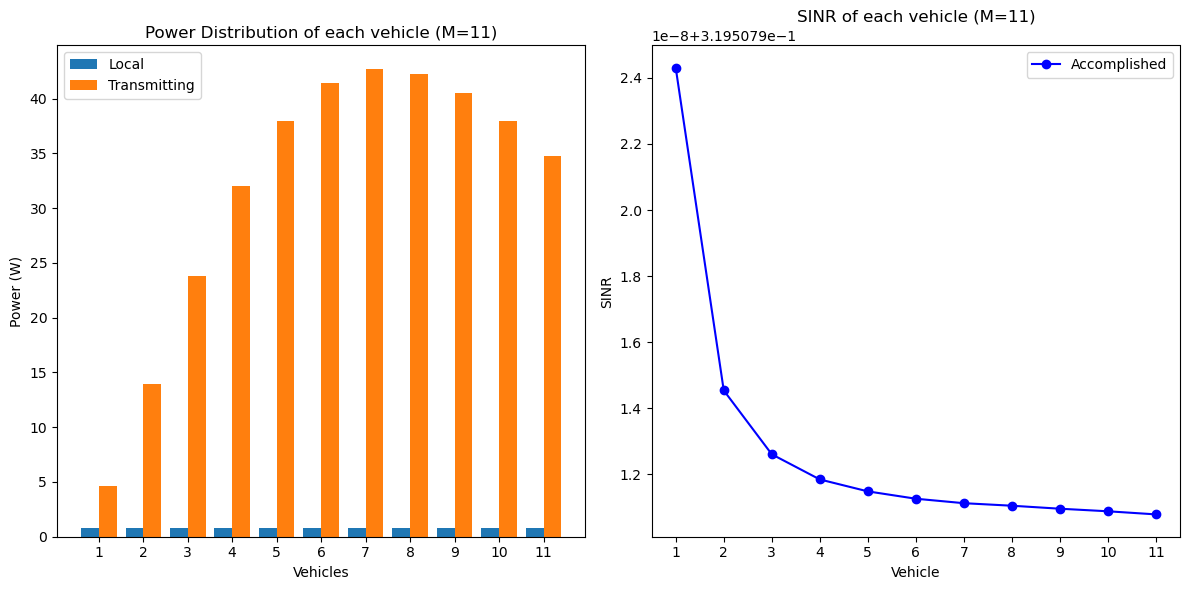

In [105]:
# Graphs
plt.figure(figsize=(12, 6))

# Power variables
plt.subplot(1, 2, 1)
x = np.arange(M)
plt.bar(x - 0.2, power_data["Local"], 0.4, label='Local')
plt.bar(x + 0.2, power_data["Transmitting"], 0.4, label='Transmitting')
plt.xticks(x, [f"{i+1}" for i in range(M)])
plt.xlabel("Vehicles")
plt.ylabel("Power (W)")
plt.title(f"Power Distribution of each vehicle (M={M})")
plt.legend()

# SINR
plt.subplot(1, 2, 2)
plt.plot(sinr_achieved, 'bo-', label='Accomplished')
plt.xticks(range(M), [f"{i+1}" for i in range(M)])
plt.xlabel("Vehicle")
plt.ylabel("SINR")
plt.title(f"SINR of each vehicle (M={M})")
plt.legend()

plt.tight_layout()
plt.show()

In [104]:
# Results table
from tabulate import tabulate

table = []
for m in range(M):
    table.append([
        m+1,
        f"{distances[m]} m",
        f"{power_data['Local'][m]:.4f} W",
        f"{power_data['Transmitting'][m]:.4f} W",
        f"{sinr_achieved[m]:.4f}"
    ])

print("\nDetailed results for each vehicle:")
print(tabulate(table, 
               headers=["Vehícle", "Distance", "Local P.", "P. Transmitting", "SINR"], 
               tablefmt="grid"))


Detailed results for each vehicle:
+-----------+------------+------------+-------------------+--------+
|   Vehícle | Distance   | Local P.   | P. Transmitting   |   SINR |
+===========+============+============+===================+========+
|         1 | 3 m        | 0.8000 W   | 4.6009 W          | 0.3195 |
+-----------+------------+------------+-------------------+--------+
|         2 | 6 m        | 0.8000 W   | 13.9474 W         | 0.3195 |
+-----------+------------+------------+-------------------+--------+
|         3 | 9 m        | 0.8000 W   | 23.7828 W         | 0.3195 |
+-----------+------------+------------+-------------------+--------+
|         4 | 12 m       | 0.8000 W   | 32.0426 W         | 0.3195 |
+-----------+------------+------------+-------------------+--------+
|         5 | 15 m       | 0.8000 W   | 37.9434 W         | 0.3195 |
+-----------+------------+------------+-------------------+--------+
|         6 | 18 m       | 0.8000 W   | 41.4082 W         | 0.3195 